# Molecular Dynamics and Statistical Mechanics



Please complete each task/part by modifying or adding code/markdown cells within each section.

# Section One - Understanding the Code

### <font color='red'>Please put your name below</font>

## Part 1

Below is a (relatively) simple code designed to run a molecular dynamics simulation of Lennard-Jones particles in the microcanonical ensemble, i.e. at constant *N*, *V*,and *E*.  While this code is completely functional, it is not well-documented. To begin, please add comments in the code to clearly document what the program is doing.  Perform this for all functions and for all code within each function.  You do not need to comment on the lines containing the  `@jit`  statements.

In [1]:
import numpy as np
from numba import double, jit, types
import matplotlib.pyplot as plt

def getParams(rho):
    params = np.zeros(4)
    rCut = 2.5 # cut-off point of walls probably
    params[0] = rCut
    params[1] = rCut*rCut  
    rc2i = 1.0/params[1]
    rc6i = rc2i*rc2i*rc2i
    params[2] = rc6i*(rc6i-1.0)
    params[3] = (16.0/3.0)*np.pi*rho*rho*((2.0/3.0)*(np.power(rCut,-9.0))-np.power(rCut,-3.0))
    return params

def getData():
    data = {} 
    data['eKin'] = []
    data['ePot'] = []
    data['pres'] = []
    data['temp'] = []
    data['time'] = []
    return data
    

@jit(types.Tuple((double, double))(double[:,:]),nopython=True)
def getKinetic(V):
    
    n_atoms = len(V[0])
    kTot = 0.0
    temp = 0.0
    
    for i in range(n_atoms):
        kTot += V[0,i]*V[0,i] + V[1,i]*V[1,i] + V[2,i]*V[2,i]
        
    kTot = kTot / 2
    
    temp = (2 * kTot) / (3 * n_atoms)
    
    return kTot,temp
    

@jit(types.Tuple((double[:,:], double, double))(double[:,:], double[:], double[:]),nopython=True)
def lennardjones(U, box, params):
    
    n_atoms = len(U[0])

    f = np.zeros((3, n_atoms))

    ePot = 0.0
    vir = np.zeros(3)
    virTotal = 0.0

    for i in range(n_atoms):
        for j in range(n_atoms):
            
            if i > j:

                dx  = U[0,j] - U[0,i]
                dy  = U[1,j] - U[1,i]
                dz  = U[2,j] - U[2,i]

                dx  -= box[0] * np.rint(dx/box[0])
                dy  -= box[1] * np.rint(dy/box[1])
                dz  -= box[2] * np.rint(dz/box[2])

                r2 = dx*dx + dy*dy + dz*dz

                if(r2 < params[1]):
                
                    r2i = 1.0 / r2
                    r6i = r2i*r2i*r2i

                    ePot = ePot + r6i*(r6i-1.0) - params[2]

                    ftmp = 48.0 * r6i*(r6i- 0.5) * r2i
                    
                    fx = ftmp * dx
                    fy = ftmp * dy
                    fz = ftmp * dz
                    
                    f[0,i] -= fx
                    f[1,i] -= fy
                    f[2,i] -= fz
                    f[0,j] += fx
                    f[1,j] += fy
                    f[2,j] += fz
                    
                    vir[0] += fx * dx
                    vir[1] += fy * dy
                    vir[2] += fz * dz
                                 
    ePot = ePot * 4.0
    virTotal = np.mean(vir)
    return f,ePot,virTotal


def initialize_positions(n_atoms, rho):
    
    pos = np.zeros((3, n_atoms))
    nPerDim = int(np.ceil(pow(n_atoms,(1.0/3.0))))
    vol = n_atoms/rho
    lenWhole = np.power(vol,(1.0/3.0))
    
    counter = 0
    for i in range(0,nPerDim):
        for j in range(0,nPerDim):
            for k in range(0,nPerDim):
                if (counter < n_atoms):
                    pos[0,counter] = (i+0.5)*lenWhole/nPerDim
                    pos[1,counter] = (j+0.5)*lenWhole/nPerDim
                    pos[2,counter] = (k+0.5)*lenWhole/nPerDim
                    counter += 1
    return pos

def initialize_box(n_atoms, rho):
    
    box = np.zeros(3)
    vol = n_atoms/rho
    lenWhole = np.power(vol,(1.0/3.0))
    box[0] = box[1] = box[2] = lenWhole
    return box

def initialize_velocities(n_atoms,temp):

    vel = np.random.normal(0.0,np.sqrt(temp),(3,n_atoms))
    mean = np.mean(vel,axis=1)
    for i in range(3):
        vel[i] -= mean[i]
    return vel

@jit(double[:,:](double[:,:], double, double),nopython=True)
def scale_velocities(vel,target,temp):

    factor = np.sqrt(target/temp)
    return vel*factor


def runSimulation(temperature, n_atoms, rho, n_steps_eq, n_steps_prod):
    
    pos = initialize_positions(n_atoms, rho)
    box = initialize_box(n_atoms, rho)
    vel = initialize_velocities(n_atoms, temperature)
    params = getParams(rho)
    data= getData()
    
    
    if (box[0] < 2*params[0]):
        print("Box size too small. Try adding more atoms or reducing the density.")
        return
    
    
    n_steps_tot = n_steps_eq + n_steps_prod
    blockTemp = 500
    blockData = 50
    dt = 0.0005

    force,ePot,virial = lennardjones(pos,box,params)
    tempBlock = 0.0
    presBlock = 0.0

    print("Starting equilibration...")
    
    for i in range(n_steps_tot):
        
        if i == n_steps_eq:
            print("Finished equilibration, beginning production...")
        
        
        pos += vel * dt + 0.5 * force * dt * dt
        
        force0 = force[:]
        
        force,ePot,virial = lennardjones(pos, box, params) 
     
        vel += 0.5 * (force + force0) * dt
     
        kTot,temp = getKinetic(vel)
        tempBlock += temp
        presBlock += (rho*temp) + (virial/(box[0]*box[1]*box[2])) + params[3]
        
        if (i+1)%blockData == 0:
            data['eKin'].append(kTot)
            data['ePot'].append(ePot)
            data['temp'].append(temp)
            data['pres'].append(presBlock/blockData)
            data['time'].append((i+1)*dt)
            presBlock = 0.0
                                   
        if (i+1)%blockTemp == 0 and i < n_steps_eq:
            avgTemp = tempBlock/blockTemp
            vel = scale_velocities(vel,temperature,avgTemp)
            tempBlock = 0.0
     
        if (i+1)%5000 == 0 and (i+1) <= n_steps_eq:
            print("{0:.2f}% done".format((i+1)*100/n_steps_eq))
            
        if (i+1)%5000 == 0 and (i+1) > n_steps_eq:
            print("{0:.2f}% done".format((i+1-n_steps_eq)*100/n_steps_prod))

    return data


## Part 2

Based on your understanding of the code, write an expression below that relates temperature to particle velocities in the cell below (using markdown).

## Part 3

Test your documented code by running a simulation.  The code snippet below shows a sample input for the program; you may wish to run the simulation for more/fewer timesteps or with more/fewer particles.  In general, you will obtain more statistically meaningful results with longer/larger simulations (i.e. more data!), but it will take longer to run. The density $N/V$ should be in the range 0.05-0.3 and the temperature $T^*$ should be in the range 1.5-2.0.

In the cells below, use python's graphing packages to show that after a brief "equilibration" period, your code leads to stable average values of kinetic/potential energy, temperature, and pressure. Verify that the total energy is conserved during the "production" portion of the simulation.

In [2]:
temperature = 1.5
n_atoms = 200
density = 0.2
eq_steps = 5000
prod_steps = 5000
data = runSimulation(temperature, n_atoms, density, eq_steps, prod_steps)

Starting equilibration...
100.00% done
Finished equilibration, beginning production...
100.00% done


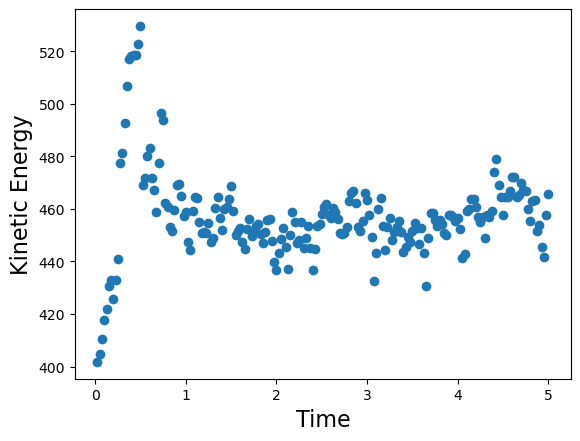

In [3]:
# example plot
plt.scatter(data["time"], data["eKin"])
plt.xlabel("Time", fontsize=16)
plt.ylabel("Kinetic Energy", fontsize=16)
plt.show()

## Part 4

We typically use a "cut-off" radius $r_{c}$ to speed up calculation - particles separated by distances larger than this value do not exert forces on one another.  However, $r_{c}$ cannot be larger than half of the box length.  Why is that?  Answer in the cell below (using markdown).


## Part 5

By examining your code, explain how the pressure of the Lennard-Jones fluid is calculated. How does the pressure arise in the system?


# Section Two - Connecting with Reality

Your program operates in "reduced units."  These units are related to real quantities through the following equations:

$$ T^* = \frac{k_B T}{\epsilon} $$

$$ \rho^* = \sigma^3 \rho $$

$$ t^* = t \sqrt{\frac{\epsilon}{m\sigma^2}} $$

where $m$ is the mass of the particles. The code (as provided) implicitly uses $\sigma = 1$ and $\epsilon=1$. The reason for using these vales is based on the principle of corresponding states; any two fluids interacting through a LJ potential behave in exactly the same way, provided you compare their properties in the appropriately reduced units. For instance consider fluid $A$ with $\sigma_A = 1$ and fluid $B$ with $\sigma_B = 2$. You could use the results of your simulation with $\sigma = 1$ (i.e. fluid $A$ at a given density (say $\rho_A^* = 0.5$) to determine the properties of the other fluid at a different density ( $\rho_B^* = 0.5/\sigma_B^3 = 0.125$)




## Part Six

Based on the definitions of reduced units above, provide a definition of the reduced pressure in the cell below (in markdown).

## Part Seven

Let's say we're interested in the properties of methane, whose Lennard-Jones parameters are shown below.

$$ \sigma = 3.73 \text{Ang.}$$


$$ \frac{\epsilon}{k_B} = 147.9 K $$

Based on this data, what was the size of the timestep you used in Part 3 above in real units (seconds)? How long was your simulation, also in real units? What were the real values of temperature and pressure of your system (in $K$ and bar, respectively)?  Answer in the cell below.

## Part Eight

The (truncated) virial equation of state for methane is given below:

$$ P = \rho R T \left ( 1 + B \rho_r \right ) $$

$$ B = B_0 + \frac{B_1}{T_r} + \frac{B_2}{T_r^2} + \frac{B_3}{T_r^3}$$

$$ B_0 = 0.440 \\ B_1 = -1.171 \\ B_2 = -0.236 \\ B_3 = -0.210 $$

where $\rho_r \equiv \rho/\rho_c$ is the density relative to the critical density and $T_r = T/T_c$ is the temperature relative to the critical temperature. For methane, $\rho_c = 10.1 mol/L$ and $T_c = 190.6 K$. 
In the cell(s) below, verify the accuracy of this equation at a reduced temperature of $T^* = 2.0$. For what values of $\rho$ does it break down? To answer this question, you will need to run the simulation at several densities in the range of $\rho = 0.05-0.3$. Compare the pressure obtained in simulations to that predicted by the virial equation. Create a plot of simulated and predicted pressures as a function of density. Perform all calculations in reduced units and explain your results.

## Part Nine

Now we are interested in comparing our simulation results to experimental values.  For a reduced temperature of $T^* = 2.0$, simulate a broader range of densities $\rho^* = 0.05 - 0.5$. Now, use the [NIST Chemistry WebBook](https://webbook.nist.gov/chemistry/fluid/) to obtain experimental values for the pressure of methane at the corresponding real temperature/densitites and plot this data alongside your simulation results and the predictions of the virial equation of state given above.  How does your simulation data compare over the range of densities? Are your simulations more or less accurate than the virial equation?

# Section Three - Chemical Potential

When we studied the canonical ensemble, we found that the chemical potential could be expressed as:

$$ \frac{\mu}{T} = - \left (  \frac{\partial S}{\partial N} \right )_{V,E}$$

In the microcanonical ensemble, the entropy $S$ is related to the number of accessible states $S = k_B ln\Omega(N,V,E)$. It can be shown that in order to calculate the above derivative, one needs to compute $\Omega(N+1,V,E)/\Omega(N,V,E)$, which would be very difficult in ordinary simulations.

An alternative approach was suggested by Benjamin Widom [*J. Chem. Phys.* **39**, 2808-2812 (1963)].  Once an $NVE$ simulation has reached equilibrium, a virtual test particle is placed randomly into the fluid and the change in total internal energy $\Delta U$ is calculated. The test particle is then removed before the simulation is allowed to integrate to the next time step. This process is then repeated throughout the simulation and the "excess" chemical potential is calculated from the following equation:

$$ \mu^{ex} = \mu - \mu^{ideal} = -k_B \langle T \rangle ln \left [ \langle T \rangle^{-3/2} \langle T^{3/2} e^{-\Delta U/k_B T} \rangle \right ] $$





## Part Ten

Using the ideas from the Widom method above, modify the MD code above to calculate the chemical potential of methane (in SI units) at $\rho^* = 0.1$ and $T^* = 2.0$. Perform your calculations at a variety of system sizes, e.g. $N = 100, 200, 500, 1000$. Note that the simulation time scales as $N^2$ so the larger simulations may take some time. Comment on your results. Note that you will need to calculate the ideal component, $\mu^{ideal}$ analytically.